# Previsão de preços com LSTM — V4

> **Aviso:** projeto educacional. Nada aqui é recomendação de investimento.

**O que mudou em relação à V3**

1. **Entradas estacionárias** — o modelo não recebe mais preço, médias móveis ou volume em valor absoluto, só medidas *relativas* (retornos, distância às médias, volatilidade, RSI, volume relativo). Assim as entradas do teste ficam na mesma faixa do treino.
2. **Treino / validação / teste separados** — o `EarlyStopping` olha a validação; o teste só é usado uma vez, no final.
3. **Avaliação contra baselines** — o LSTM é comparado com o *random walk* (retorno zero), a média histórica e uma regressão linear (Ridge). Sem isso não dá para saber se o modelo aprendeu algo.
4. **Validação walk-forward** — o processo é repetido em vários períodos de teste, para o resultado não depender de um único corte.
5. **Previsão direta dos 30 dias + intervalo de confiança** — o modelo prevê os 30 retornos de uma vez (sem realimentar a própria previsão). O modelo final é re-treinado com todos os dados, e a incerteza vem dos erros reais na validação, ajustados à volatilidade atual.

## 0. Configuração

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import tensorflow as tf
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

TICKER = "NVDA"        # NASDAQ/NYSE ou B3 (ex: "PETR4.SA")
START = "2015-01-01"
END = "2026-11-13"     # data fixa = resultados reproduzíveis (None = até hoje, sem cache)
SEQ_LEN = 60           # dias de histórico em cada janela de entrada
HORIZON = 30           # dias úteis previstos
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15   # o restante (15%) é teste

RUN_WALK_FORWARD = True  # treina N_FOLDS modelos extras (alguns minutos a mais)
N_FOLDS = 4              # períodos de teste no walk-forward
WF_FRAC = 0.30           # fração final da série coberta pelo walk-forward

FINAL_REFIT = True       # re-treina com todos os dados antes da previsão final
N_SIMULATIONS = 1000     # caminhos simulados para o intervalo de confiança
VOL_WINDOW = 63          # dias (~3 meses) usados para medir a volatilidade atual
SEED = 42

tf.keras.utils.set_random_seed(SEED)  # fixa as sementes do Python, NumPy e TensorFlow
# Obs.: em GPU algumas operações não são determinísticas; pequenas variações são normais.

## 1. Dados

Com `END` definido, o download é salvo em `data/` e reutilizado nas próximas execuções — assim o resultado não muda só porque o Yahoo atualizou a série.

In [2]:
def load_prices(ticker, start, end, cache_dir="data"):
    cache = Path(cache_dir) / f"{ticker}_{start}_{end}.csv"
    if end is not None and cache.exists():
        return pd.read_csv(cache, index_col=0, parse_dates=True)

    raw = yf.download(ticker, start=start, end=end, auto_adjust=True, progress=False)
    if raw.empty:
        raise ValueError(f"Nenhum dado retornado para {ticker!r}")
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    df = raw[["Close", "Volume"]].dropna()

    if end is not None:
        cache.parent.mkdir(exist_ok=True)
        df.to_csv(cache)
    return df


prices = load_prices(TICKER, START, END)
print(f"{TICKER}: {len(prices)} pregões de {prices.index[0].date()} a {prices.index[-1].date()}")

NVDA: 2984 pregões de 2015-01-02 a 2026-11-12


## 2. Features estacionárias

Na V3, `Close`, `MA7`, `MA21` e `Volume` entravam em valor absoluto. Como o scaler é ajustado só no treino, quando o preço do teste passa do máximo do treino as entradas saem muito da faixa que a rede conhece. Aqui todas as features são relativas ao próprio preço/volume recente.

In [3]:
def rsi_wilder(close, window=14):
    """RSI com a suavização de Wilder (média exponencial com alpha = 1/window)."""
    delta = close.diff()
    gain = delta.clip(lower=0).ewm(alpha=1 / window, adjust=False, min_periods=window).mean()
    loss = (-delta.clip(upper=0)).ewm(alpha=1 / window, adjust=False, min_periods=window).mean()
    rsi = 100 - 100 / (1 + gain / loss.replace(0, np.nan))
    rsi = rsi.mask(loss.eq(0) & gain.gt(0), 100.0)  # só altas no período
    rsi = rsi.mask(loss.eq(0) & gain.eq(0), 50.0)   # nenhuma variação
    return rsi


def build_features(df):
    close = df["Close"]
    log_volume = np.log1p(df["Volume"])
    ma7, ma21 = close.rolling(7).mean(), close.rolling(21).mean()
    log_ret = np.log(close).diff()

    feats = pd.DataFrame({
        "log_ret": log_ret,                               # retorno do dia
        "ret_5d": np.log(close / close.shift(5)),         # momentum de 1 semana
        "ret_21d": np.log(close / close.shift(21)),       # momentum de 1 mês
        "gap_ma7": close / ma7 - 1,                       # distância à MA7
        "gap_ma21": close / ma21 - 1,                     # distância à MA21
        "ma7_vs_ma21": ma7 / ma21 - 1,                    # cruzamento de médias
        "vol_7d": log_ret.rolling(7).std(),               # volatilidade curta
        "vol_21d": log_ret.rolling(21).std(),             # volatilidade longa
        "rsi": rsi_wilder(close) / 100 - 0.5,             # RSI centrado em 0
        "volume_rel": log_volume - log_volume.rolling(21).mean(),  # volume vs. média
    }, index=df.index)
    return feats.replace([np.inf, -np.inf], np.nan).dropna()


features = build_features(prices)
rets = features["log_ret"].to_numpy()  # alvo: retornos logarítmicos diários
features.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
log_ret,2963.0,0.0020,0.0302,-0.2077,-0.0130,0.0025,0.0175,0.2609
ret_5d,2963.0,0.0100,0.0645,-0.3335,-0.0264,0.0123,0.0472,0.3099
ret_21d,2963.0,0.0429,0.1302,-0.4598,-0.0301,0.0462,0.1240,0.4417
gap_ma7,2963.0,0.0063,0.0394,-0.2228,-0.0157,0.0072,0.0288,0.2226
gap_ma21,2963.0,0.0216,0.0731,-0.2827,-0.0203,0.0237,0.0656,0.3051
ma7_vs_ma21,2963.0,0.0146,0.0500,-0.1936,-0.0134,0.0160,0.0465,0.1892
vol_7d,2963.0,0.0265,0.0149,0.0033,0.0162,0.0230,0.0320,0.1212
vol_21d,2963.0,0.0278,0.0117,0.0088,0.0196,0.0244,0.0339,0.0878
rsi,2963.0,0.0604,0.1244,-0.3111,-0.0252,0.0605,0.1507,0.3917
volume_rel,2963.0,-0.0001,0.3469,-1.4932,-0.2250,-0.0457,0.1682,1.8952


## 3. Treino / validação / teste

A divisão é cronológica. Cada amostra é uma janela de `SEQ_LEN` dias de entrada e os `HORIZON` retornos seguintes como alvo. Uma amostra só pertence a um conjunto se **todo o alvo** cair dentro dele, então nenhum retorno da validação ou do teste é usado no treino. O scaler é ajustado **só no treino**.

In [4]:
def make_windows(X_scaled, a, b):
    """Janelas cujo alvo (os HORIZON retornos seguintes) cai inteiro em [a, b).
    A entrada pode usar dias anteriores a `a`: é passado, não vaza informação."""
    X, y = [], []
    for t in range(max(a - 1, SEQ_LEN - 1), b - HORIZON):
        X.append(X_scaled[t - SEQ_LEN + 1 : t + 1])  # features até o dia t (inclusive)
        y.append(rets[t + 1 : t + HORIZON + 1])     # retornos de t+1 a t+HORIZON
    if not X:
        raise ValueError(
            f"O período {features.index[a].date()} → {features.index[b - 1].date()} é curto demais "
            f"para janelas de {SEQ_LEN} + {HORIZON} dias. Use um START mais antigo ou um HORIZON menor."
        )
    return np.array(X), np.array(y)


def prepare_split(train_end, val_end, test_end):
    """Treino = [0, train_end), validação = [train_end, val_end), teste = [val_end, test_end)."""
    scaler = StandardScaler().fit(features.iloc[:train_end])
    X_scaled = scaler.transform(features)
    return {
        "X_scaled": X_scaled,
        "ret_scale": rets[:train_end].std(),   # o alvo é dividido pela volatilidade do treino
        "train_mean": rets[:train_end].mean(),
        "train": make_windows(X_scaled, 0, train_end),
        "val": make_windows(X_scaled, train_end, val_end),
        "test": make_windows(X_scaled, val_end, test_end),
    }


n = len(features)
n_train = int(n * TRAIN_FRAC)
n_val = int(n * VAL_FRAC)
for name, (a, b) in {"treino": (0, n_train), "validação": (n_train, n_train + n_val),
                     "teste": (n_train + n_val, n)}.items():
    print(f"{name:>10}: {features.index[a].date()} → {features.index[b - 1].date()} ({b - a} dias)")

split = prepare_split(n_train, n_train + n_val, n)
X_val, y_val = split["val"]  # usados de novo na seção 7
print(f"\nAmostras — treino: {len(split['train'][0])}, validação: {len(X_val)}, "
      f"teste: {len(split['test'][0])}")

    treino: 2015-02-03 → 2023-04-28 (2074 dias)
 validação: 2023-05-01 → 2025-02-05 (444 dias)
     teste: 2025-02-06 → 2026-11-12 (445 dias)

Amostras — treino: 1985, validação: 415, teste: 416


**Checagem:** as entradas do teste ficam na mesma faixa que as do treino?

In [5]:
X_scaled = split["X_scaled"]
check = pd.DataFrame({
    "treino (p99 |z|)": np.percentile(np.abs(X_scaled[:n_train]), 99, axis=0),
    "teste (p99 |z|)": np.percentile(np.abs(X_scaled[n_train + n_val:]), 99, axis=0),
}, index=features.columns).round(2)
display(check)

# Como era na V3: MinMax ajustado no preço do treino
close_train = prices["Close"].loc[: features.index[n_train - 1]]
close_test = prices["Close"].loc[features.index[n_train + n_val]:]
v3_max = (close_test.max() - close_train.min()) / (close_train.max() - close_train.min())
print(f"Na V3, o Close escalonado do teste chegaria a {v3_max:.2f} (o treino só via valores entre 0 e 1).")

,treino (p99 |z|),teste (p99 |z|)
log_ret,3.26,2.73
ret_5d,3.08,2.34
ret_21d,2.87,2.15
gap_ma7,3.10,2.51
gap_ma21,2.99,2.37
ma7_vs_ma21,2.83,2.13
vol_7d,3.72,3.57
vol_21d,3.51,2.28
rsi,2.32,2.16
volume_rel,3.14,2.55


Na V3, o Close escalonado do teste chegaria a 7.29 (o treino só via valores entre 0 e 1).


## 4. Modelos

**LSTM** com saída `Dense(HORIZON)`: prevê os 30 retornos diários **de uma vez**. Na V3 a previsão era recursiva — cada previsão realimentava as features (volatilidade, RSI) com valores suaves demais, e depois de poucos passos a rede recebia entradas que nunca tinha visto.

**Ridge (regressão linear regularizada)**: usa só as features do último dia da janela. É um baseline barato e honesto — se o LSTM não for melhor que ele, a complexidade extra não está se pagando. A força da regularização (`alpha`) é escolhida pela validação.

Epoch 1/100


32/32 - 5s - 142ms/step - loss: 1.0342 - val_loss: 1.0696


Epoch 2/100


32/32 - 2s - 63ms/step - loss: 1.0301 - val_loss: 1.0675


Epoch 3/100


32/32 - 2s - 67ms/step - loss: 1.0293 - val_loss: 1.0665


... (31 outputs left out)

32/32 - 2s - 57ms/step - loss: 1.0026 - val_loss: 1.0914


Epoch 20/100


32/32 - 2s - 66ms/step - loss: 1.0012 - val_loss: 1.0986



LSTM: melhor época = 10 | Ridge: alpha escolhido = 100000


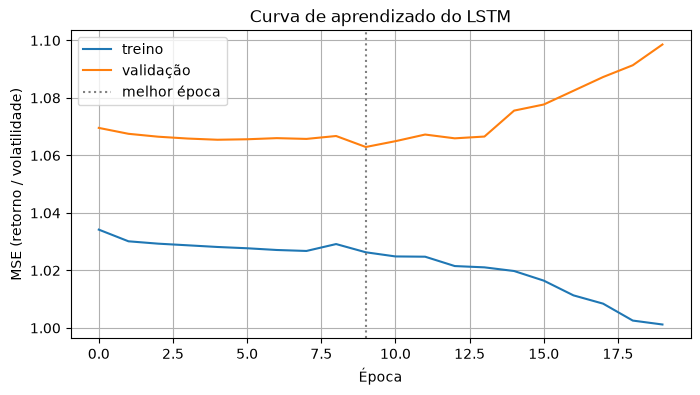

In [6]:
RIDGE_ALPHAS = [1, 10, 100, 1_000, 10_000, 100_000]


def rmse(pred, true):
    return float(np.sqrt(np.mean((pred - true) ** 2)))


def build_lstm(n_features):
    model = Sequential([
        Input(shape=(SEQ_LEN, n_features)),
        LSTM(64, return_sequences=True),
        Dropout(0.2),
        LSTM(32),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(HORIZON),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return model


def train_lstm(sp, verbose=0):
    (X_tr, y_tr), (X_va, y_va) = sp["train"], sp["val"]
    model = build_lstm(X_tr.shape[2])
    history = model.fit(
        X_tr, y_tr / sp["ret_scale"],
        validation_data=(X_va, y_va / sp["ret_scale"]),  # validação, NÃO o teste
        epochs=100,
        batch_size=64,
        callbacks=[EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)],
        verbose=verbose,
    )
    return model, history


def lstm_predict(model, X, ret_scale):
    # chamada direta em vez de model.predict(): evita re-compilar a função a cada modelo novo
    return model(X.astype("float32"), training=False).numpy() * ret_scale


def train_ridge(sp):
    (X_tr, y_tr), (X_va, y_va) = sp["train"], sp["val"]
    candidates = [Ridge(alpha=a).fit(X_tr[:, -1], y_tr) for a in RIDGE_ALPHAS]
    return min(candidates, key=lambda m: rmse(m.predict(X_va[:, -1]), y_va))


model, history = train_lstm(split, verbose=2)  # uma linha por época
ridge = train_ridge(split)
best_epochs = int(np.argmin(history.history["val_loss"])) + 1
print(f"\nLSTM: melhor época = {best_epochs} | Ridge: alpha escolhido = {ridge.alpha}")

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="treino")
plt.plot(history.history["val_loss"], label="validação")
plt.axvline(best_epochs - 1, color="gray", linestyle=":", label="melhor época")
plt.xlabel("Época")
plt.ylabel("MSE (retorno / volatilidade)")
plt.title("Curva de aprendizado do LSTM")
plt.legend()
plt.grid(True)
plt.show()

## 5. Avaliação no teste vs. baselines

- **Zero (random walk):** prevê que o preço não muda. É o baseline mais difícil de bater em ações.
- **Média do treino (drift):** prevê sempre o retorno médio diário do treino.
- **Ridge:** regressão linear sobre as mesmas features.

Métricas: RMSE dos retornos (quanto menor, melhor) e acerto de direção (% de vezes que o sinal do retorno previsto bate com o real). O random walk não tem direção, então fica vazio.

> As janelas de 30 dias se sobrepõem, então as amostras do teste são muito correlacionadas. Diferenças de poucos % entre os modelos **não** são estatisticamente significativas — por isso a seção 6 repete o teste em vários períodos.

In [7]:
METRIC_FORMATS = {
    "RMSE retorno 1d": "{:.4f}",
    "RMSE retornos diários 1–30d": "{:.4f}",
    "RMSE retorno acumulado 30d": "{:.4f}",
    "Acerto direção 1d": "{:.1%}",
    "Acerto direção 30d": "{:.1%}",
}


def hit_rate(pred, true):
    if np.allclose(pred, 0):
        return np.nan  # previsão zero não tem direção
    return float(np.mean(np.sign(pred) == np.sign(true)))


def all_predictions(sp, lstm_model, ridge_model):
    X, y = sp["test"]
    preds = {
        "LSTM": lstm_predict(lstm_model, X, sp["ret_scale"]),
        "Ridge (linear)": ridge_model.predict(X[:, -1]),
        "Zero (random walk)": np.zeros_like(y),
        "Média do treino (drift)": np.full_like(y, sp["train_mean"]),
    }
    return preds, y


def compare_models(preds, y_true):
    return pd.DataFrame({
        name: {
            "RMSE retorno 1d": rmse(pred[:, 0], y_true[:, 0]),
            "RMSE retornos diários 1–30d": rmse(pred, y_true),
            "RMSE retorno acumulado 30d": rmse(pred.sum(1), y_true.sum(1)),
            "Acerto direção 1d": hit_rate(pred[:, 0], y_true[:, 0]),
            "Acerto direção 30d": hit_rate(pred.sum(1), y_true.sum(1)),
        }
        for name, pred in preds.items()
    }).T


def print_vs_random_walk(results):
    for model_name in ["LSTM", "Ridge (linear)"]:
        for col in ["RMSE retorno 1d", "RMSE retorno acumulado 30d"]:
            gain = 1 - results.loc[model_name, col] / results.loc["Zero (random walk)", col]
            verdict = "melhor" if gain > 0 else "pior"
            print(f"{model_name} — {col}: {abs(gain):.1%} {verdict} que o random walk")


preds, y_true = all_predictions(split, model, ridge)
results = compare_models(preds, y_true)
display(results.style.format(METRIC_FORMATS, na_rep="—"))
print_vs_random_walk(results)

,RMSE retorno 1d,RMSE retornos diários 1–30d,RMSE retorno acumulado 30d,Acerto direção 1d,Acerto direção 30d
LSTM,0.0264,0.0260,0.1334,53.1%,60.6%
Ridge (linear),0.0263,0.0259,0.1226,53.1%,62.3%
Zero (random walk),0.0264,0.0259,0.1265,—,—
Média do treino (drift),0.0263,0.0259,0.1225,53.1%,62.3%


LSTM — RMSE retorno 1d: 0.1% pior que o random walk
LSTM — RMSE retorno acumulado 30d: 5.4% pior que o random walk
Ridge (linear) — RMSE retorno 1d: 0.2% melhor que o random walk
Ridge (linear) — RMSE retorno acumulado 30d: 3.1% melhor que o random walk


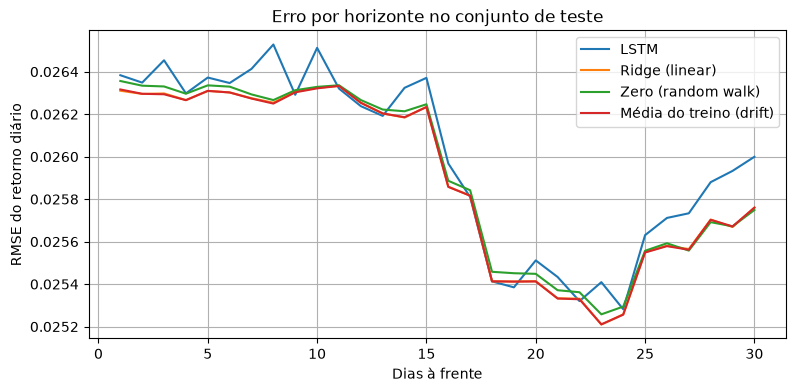

In [8]:
plt.figure(figsize=(9, 4))
for name, pred in preds.items():
    plt.plot(range(1, HORIZON + 1), np.sqrt(np.mean((pred - y_true) ** 2, axis=0)), label=name)
plt.xlabel("Dias à frente")
plt.ylabel("RMSE do retorno diário")
plt.title("Erro por horizonte no conjunto de teste")
plt.legend()
plt.grid(True)
plt.show()

## 6. Validação walk-forward

Um único período de teste pode favorecer um modelo por sorte (por exemplo, um ano de alta forte). Aqui os últimos `WF_FRAC` da série são divididos em `N_FOLDS` períodos de teste consecutivos. Em cada um, o scaler e os modelos são re-treinados **só com o que veio antes** (janela expansiva), e as métricas são calculadas no período seguinte.

Desligue com `RUN_WALK_FORWARD = False` se quiser rodar mais rápido.

In [9]:
if RUN_WALK_FORWARD:
    fold_len = int(n * WF_FRAC) // N_FOLDS
    wf_start = n - N_FOLDS * fold_len
    fold_results = []
    for k in range(N_FOLDS):
        test_start = wf_start + k * fold_len
        test_end = n if k == N_FOLDS - 1 else test_start + fold_len
        print(f"Fold {k + 1}/{N_FOLDS}: teste {features.index[test_start].date()} → "
              f"{features.index[test_end - 1].date()}")

        fold = prepare_split(test_start - n_val, test_start, test_end)
        fold_lstm, _ = train_lstm(fold)
        fold_ridge = train_ridge(fold)
        fold_preds, fold_y = all_predictions(fold, fold_lstm, fold_ridge)
        fold_results.append(compare_models(fold_preds, fold_y).assign(fold=k + 1))
        del fold_lstm

    wf = pd.concat(fold_results).rename_axis("modelo").reset_index()
    model_order = list(preds.keys())

    print("\nRMSE do retorno acumulado em 30 dias, por período de teste:")
    display(wf.pivot(index="fold", columns="modelo", values="RMSE retorno acumulado 30d")[model_order].round(4))

    print("Média dos períodos:")
    wf_mean = wf.drop(columns="fold").groupby("modelo").mean().reindex(model_order)
    display(wf_mean.style.format(METRIC_FORMATS, na_rep="—"))
    print_vs_random_walk(wf_mean)
else:
    print("Walk-forward desligado (RUN_WALK_FORWARD = False).")

Fold 1/4: teste 2023-05-02 → 2024-03-19


Fold 2/4: teste 2024-03-20 → 2025-02-06


Fold 3/4: teste 2025-02-07 → 2025-12-24


Fold 4/4: teste 2025-12-26 → 2026-11-12



RMSE do retorno acumulado em 30 dias, por período de teste:


modelo,LSTM,Ridge (linear),Zero (random walk),Média do treino (drift)
fold,,,,
1,0.1914,0.1684,0.2068,0.1692
2,0.1554,0.1532,0.1669,0.1532
3,0.1375,0.1409,0.1531,0.1409
4,0.1048,0.1133,0.1039,0.1133


Média dos períodos:


,RMSE retorno 1d,RMSE retornos diários 1–30d,RMSE retorno acumulado 30d,Acerto direção 1d,Acerto direção 30d
modelo,,,,,
LSTM,0.0286,0.0286,0.1473,52.7%,65.2%
Ridge (linear),0.0285,0.0286,0.1440,54.1%,65.2%
Zero (random walk),0.0286,0.0287,0.1577,—,—
Média do treino (drift),0.0285,0.0286,0.1441,54.1%,65.2%


LSTM — RMSE retorno 1d: 0.0% melhor que o random walk
LSTM — RMSE retorno acumulado 30d: 6.6% melhor que o random walk
Ridge (linear) — RMSE retorno 1d: 0.4% melhor que o random walk
Ridge (linear) — RMSE retorno acumulado 30d: 8.7% melhor que o random walk


## 7. Previsão dos próximos 30 dias com intervalo de confiança

Uma linha única passa uma falsa sensação de precisão. Aqui:

1. **Modelo final:** com `FINAL_REFIT = True`, o LSTM é re-treinado com **todos** os dados (incluindo validação e teste) pelo número de épocas que foi o melhor na seção 4 — assim a previsão usa o comportamento mais recente do ativo.
2. **Incerteza:** cada simulação soma à previsão um vetor de 30 erros reais do modelo na validação (o vetor inteiro, para manter a correlação entre os dias). Os erros são **centralizados** (para não herdar o viés daquele período) e **reescalados** pela razão entre a volatilidade dos últimos `VOL_WINDOW` dias e a da validação.

O resultado é a mediana e uma faixa de 90%. O intervalo é uma aproximação: ele assume que o modelo final erra de forma parecida com o modelo avaliado.

O gráfico também mostra a **linha do drift** (crescimento no ritmo médio histórico) como referência, e a célula avisa se o LSTM não superou os baselines na avaliação — nesse caso a mediana prevista não deve ser lida como sinal.

In [10]:
# 1. Erros do modelo avaliado na validação, centralizados e ajustados à volatilidade atual
residuals = y_val - lstm_predict(model, X_val, split["ret_scale"])
residuals = residuals - residuals.mean(axis=0)
vol_ratio = rets[-VOL_WINDOW:].std() / rets[n_train : n_train + n_val].std()
residuals = residuals * vol_ratio
print(f"Volatilidade atual / volatilidade da validação: {vol_ratio:.2f}")

# 2. Previsão pontual dos próximos HORIZON retornos
if FINAL_REFIT:
    final_scaler = StandardScaler().fit(features)
    final_X_scaled = final_scaler.transform(features)
    final_ret_scale = rets.std()
    X_all_windows, y_all_windows = make_windows(final_X_scaled, 0, n)
    final_model = build_lstm(X_all_windows.shape[2])
    final_model.fit(X_all_windows, y_all_windows / final_ret_scale,
                    epochs=best_epochs, batch_size=64, verbose=0)
    point = lstm_predict(final_model, final_X_scaled[-SEQ_LEN:][np.newaxis], final_ret_scale)[0]
    print(f"Modelo final re-treinado com {len(X_all_windows)} janelas por {best_epochs} épocas.")
else:
    point = lstm_predict(model, X_scaled[-SEQ_LEN:][np.newaxis], split["ret_scale"])[0]

# 3. Simulação dos caminhos de preço
rng = np.random.default_rng(SEED)
sim_returns = point + residuals[rng.integers(0, len(residuals), N_SIMULATIONS)]
last_price = float(prices["Close"].iloc[-1])
sim_paths = last_price * np.exp(np.cumsum(sim_returns, axis=1))
p5, p50, p95 = np.percentile(sim_paths, [5, 50, 95], axis=0)

Volatilidade atual / volatilidade da validação: 0.82


Modelo final re-treinado com 2874 janelas por 10 épocas.


ATENÇÃO: na avaliação, o LSTM foi 2.3% PIOR que o melhor baseline (Ridge (linear)).
A mediana abaixo não tem poder preditivo demonstrado — use o intervalo, não a linha, como leitura principal.



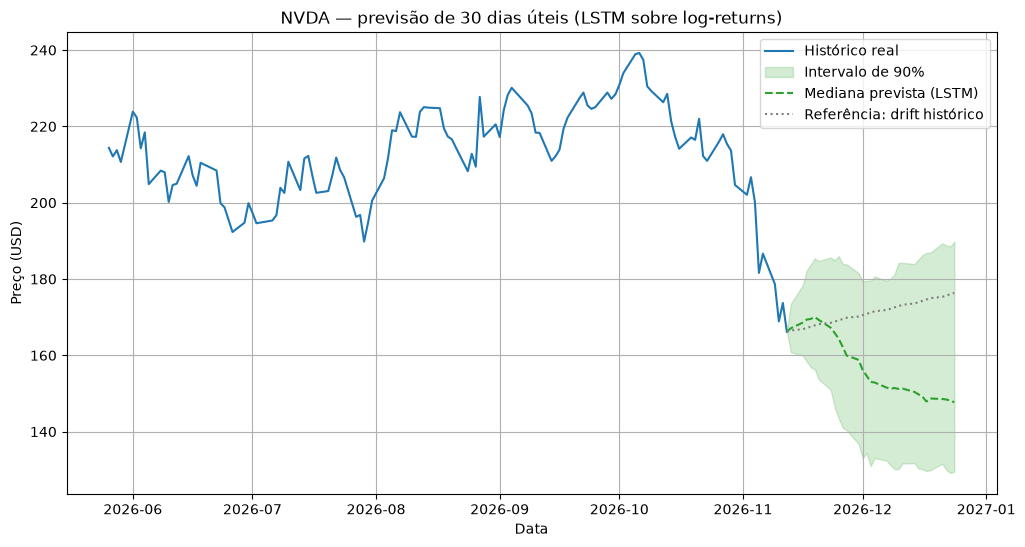

Último preço (2026-11-12): 166.19 USD
Mediana em 30 dias úteis (2026-12-24): 147.71 USD (-11.1%)
Intervalo de 90%: 129.54 a 189.83 USD
Referência (drift histórico): 176.36 USD (+6.1%)


In [11]:
# O LSTM mostrou vantagem real sobre os baselines? (walk-forward, se rodou; senão, o teste único)
skill_table = wf_mean if RUN_WALK_FORWARD else results
col = "RMSE retorno acumulado 30d"
best_baseline = skill_table.drop(index="LSTM")[col].idxmin()
lstm_edge = 1 - skill_table.loc["LSTM", col] / skill_table.loc[best_baseline, col]
if lstm_edge <= 0:
    print(f"ATENÇÃO: na avaliação, o LSTM foi {abs(lstm_edge):.1%} PIOR que o melhor baseline "
          f"({best_baseline}).\nA mediana abaixo não tem poder preditivo demonstrado — use o intervalo, "
          f"não a linha, como leitura principal.\n")
else:
    print(f"Na avaliação, o LSTM foi {lstm_edge:.1%} melhor que o melhor baseline ({best_baseline}).\n")

last_date = prices.index[-1]
# dias úteis de segunda a sexta (feriados não são descontados)
future_dates = pd.bdate_range(last_date + pd.offsets.BDay(1), periods=HORIZON)
x_fc = pd.DatetimeIndex([last_date]).append(future_dates)  # começa no último preço real

try:
    currency = yf.Ticker(TICKER).fast_info["currency"]
except Exception:
    currency = ""

hist = prices["Close"].iloc[-120:]
plt.figure(figsize=(12, 6))
plt.plot(hist.index, hist, color="tab:blue", label="Histórico real")
plt.fill_between(x_fc, np.r_[last_price, p5], np.r_[last_price, p95],
                 color="tab:green", alpha=0.2, label="Intervalo de 90%")
plt.plot(x_fc, np.r_[last_price, p50], color="tab:green", linestyle="--", label="Mediana prevista (LSTM)")
drift_path = last_price * np.exp(rets.mean() * np.arange(HORIZON + 1))
plt.plot(x_fc, drift_path, color="gray", linestyle=":", label="Referência: drift histórico")
plt.title(f"{TICKER} — previsão de {HORIZON} dias úteis (LSTM sobre log-returns)")
plt.xlabel("Data")
plt.ylabel(f"Preço ({currency})" if currency else "Preço")
plt.legend()
plt.grid(True)
plt.show()

unit = f" {currency}" if currency else ""
print(f"Último preço ({last_date.date()}): {last_price:,.2f}{unit}")
print(f"Mediana em {HORIZON} dias úteis ({future_dates[-1].date()}): "
      f"{p50[-1]:,.2f}{unit} ({p50[-1] / last_price - 1:+.1%})")
print(f"Intervalo de 90%: {p5[-1]:,.2f} a {p95[-1]:,.2f}{unit}")
print(f"Referência (drift histórico): {drift_path[-1]:,.2f}{unit} ({drift_path[-1] / last_price - 1:+.1%})")

## Conclusão e próximos passos

Se o LSTM **não** superar os baselines (random walk, drift e Ridge) nas seções 5 e 6, isso não é um bug: retornos diários de ações são quase imprevisíveis, e esse é o resultado mais comum na literatura. O valor do projeto está em medir isso de forma honesta.

**Como ler o Ridge:** se o `alpha` escolhido for o maior da grade, a regularização zerou os coeficientes e o Ridge virou, na prática, o próprio drift (só o intercepto). Isso indica que as features não têm poder preditivo linear sobre os retornos dos próximos 30 dias — um resultado útil por si só.

Ideias para continuar:
- **Ensemble de LSTMs** (vários treinos com sementes diferentes, previsão média) para reduzir a variância do modelo.
- **Features externas:** índice de mercado (S&P 500 / Ibovespa), VIX, juros.
- **Outros modelos clássicos:** ARIMA para a média e GARCH para a volatilidade.
- **Prever volatilidade em vez de preço** — ela é bem mais previsível que a direção.
- **Backtest de uma estratégia** usando o sinal do modelo, com custos de transação.